# Prediction de la RUL (UC5) - Jalon 1 : MLP

Flux du notebook :

1. Analyse exploratoire (EDA) et choix des entrees
2. Preparation des donnees (cible, decoupage par pompe, normalisation)
3. Modele de reference (9 entrees)
4. Modele optimal a 3 entrees : normalisation globale vs par regime
5. Fonction de perte : MSE vs asymetrique
6. Fenetres temporelles (k = 5, 15, 30) avec le meilleur modele
7. Synthese des resultats

## 1. Analyse exploratoire (EDA)

In [1]:
# --- Bibliotheques et reproductibilite ---
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

print("tensorflow :", tf.__version__, "| keras :", keras.__version__, "| numpy :", np.__version__)

I0000 00:00:1791637168.623001  249972 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791637171.009642  249972 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791637176.494559  249972 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


tensorflow : 2.21.0 | keras : 3.15.1 | numpy : 2.5.3


In [2]:
# --- Constantes et dossier des donnees ---
from pathlib import Path

DATA = Path("../data_UC5") if Path.cwd().name == "notebooks" else Path("data_UC5")

RUL_MAX = 125        # la RUL est plafonnee a 125 cycles
SEUIL_ALERTE = 30    # une pompe est signalee si la RUL predite < 30
SEUIL_FA = 60        # fausse alerte si la RUL reelle > 60

CAPTEURS = [f"capteur_{i}" for i in range(8)]
FEATURES = CAPTEURS + ["charge"]                    # 9 entrees = 8 capteurs + regime de charge
FEATURES_3 = ["capteur_4", "capteur_5", "charge"]   # 3 entrees du modele optimal (cf. EDA)

print("dossier data :", DATA.resolve())
print("entrees retenues pour le modele optimal :", FEATURES_3)

dossier data : /home/moussl/PycharmProjects/ProjectFM/data_UC5
entrees retenues pour le modele optimal : ['capteur_4', 'capteur_5', 'charge']


In [3]:
# --- Chargement des tableaux .npy et construction du tableau de travail ---
capteurs = np.load(DATA / "capteurs_train.npy")   # (N, 8)
charge = np.load(DATA / "charge_train.npy")        # (N,)
cycle = np.load(DATA / "cycle_train.npy")          # (N,)
pompe = np.load(DATA / "pompe_train.npy")          # (N,)
rul = np.load(DATA / "rul_train.npy")              # (N,)

df = pd.DataFrame({"pompe": pompe, "cycle": cycle, "charge": charge, "rul": rul})
df = pd.concat([df, pd.DataFrame(capteurs, columns=CAPTEURS)], axis=1)

print("df :", df.shape)

df : (2847, 12)


In [4]:
# --- Les 5 premieres lignes (un cycle par ligne) ---
df.head()

,pompe,cycle,charge,rul,capteur_0,capteur_1,capteur_2,capteur_3,capteur_4,capteur_5,capteur_6,capteur_7
0,501,1,0.8,287,64.121368,85.283852,5.703406,386.112061,2.799164,2.926858,60.545464,2940.054688
1,501,2,0.8,286,65.842484,88.605904,5.843378,382.737915,2.613886,3.232284,59.429459,2939.211670
2,501,3,0.6,285,61.027695,64.997971,4.149714,300.460449,2.635431,2.805421,59.821304,2951.151367
3,501,4,0.6,284,60.993416,65.993988,4.331102,295.942719,2.664095,2.942466,57.797825,2952.621094
4,501,5,0.6,283,61.448277,66.742538,3.861803,288.022522,2.255884,2.674360,59.544952,2945.199951


In [5]:
# --- Nombre de cycles observe par pompe ---
df.groupby("pompe")["cycle"].max()

pompe
501    288
502    318
503    337
504    155
505    386
506    288
507    369
508    180
509    151
510    375
Name: cycle, dtype: int16

In [6]:
# --- Repartition des regimes de charge ---
df["charge"].value_counts()

charge
0.8    957
0.6    948
1.0    942
Name: count, dtype: int64

In [7]:
# --- Statistiques descriptives des capteurs ---
df[CAPTEURS].describe().T

,count,mean,std,min,25%,50%,75%,max
capteur_0,2847.0,64.259354,3.792441,55.135666,61.380371,64.066513,66.433197,80.946022
capteur_1,2847.0,87.004807,17.777519,55.372734,66.862804,87.048889,106.705402,120.426399
capteur_2,2847.0,5.720295,1.197269,2.913078,4.429073,5.762125,7.052977,7.832178
capteur_3,2847.0,381.375610,79.020126,210.143555,294.395859,383.246033,471.360504,515.012634
capteur_4,2847.0,2.972434,0.767904,2.066233,2.549812,2.729548,2.995620,6.782763
capteur_5,2847.0,3.224263,0.785955,1.964009,2.828746,3.061193,3.310765,7.960818
capteur_6,2847.0,62.292007,2.278130,56.621468,60.611128,62.327423,63.746716,71.312256
capteur_7,2847.0,2943.461914,4.821505,2926.181885,2940.097656,2943.570557,2946.876343,2957.728760


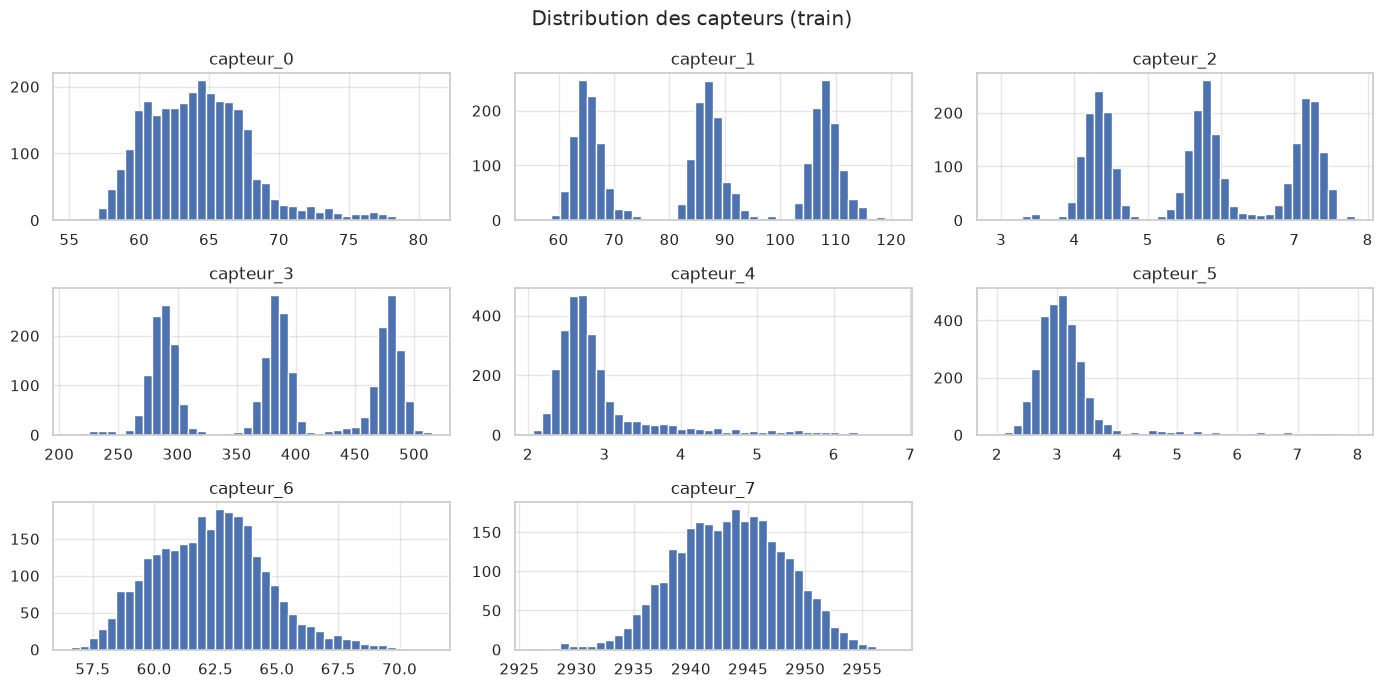

In [8]:
# --- Distribution des capteurs ---
df[CAPTEURS].hist(figsize=(14, 7), bins=40)
plt.suptitle("Distribution des capteurs (train)")
plt.tight_layout()
plt.show()

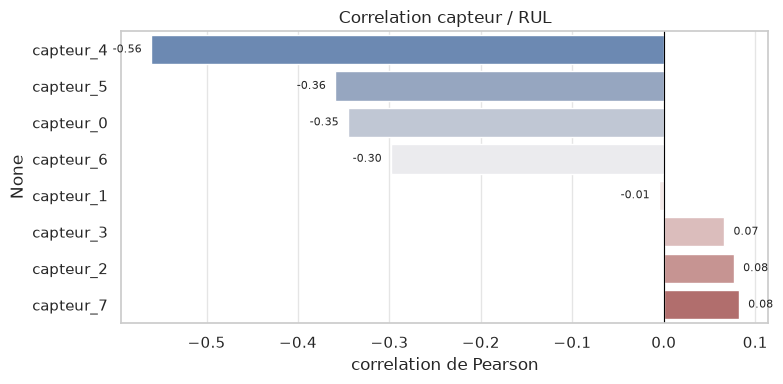

In [9]:
# --- Correlation capteur / RUL : sert a selectionner les capteurs utiles ---
corr = df[CAPTEURS + ["rul"]].corr()["rul"].drop("rul").sort_values()

plt.figure(figsize=(8, 4))
sns.barplot(x=corr.values, y=corr.index, hue=corr.index, palette="vlag", legend=False)
for i, v in enumerate(corr.values):
    plt.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}",
             va="center", ha="left" if v >= 0 else "right", fontsize=8)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation capteur / RUL")
plt.xlabel("correlation de Pearson")
plt.tight_layout()
plt.show()

Les capteurs **capteur_4** et **capteur_5** presentent la meilleure correlation avec la RUL, et le regime de charge **charge** module fortement les mesures : ces 3 variables forment le jeu d'entrees reduit `FEATURES_3` utilise dans la suite.

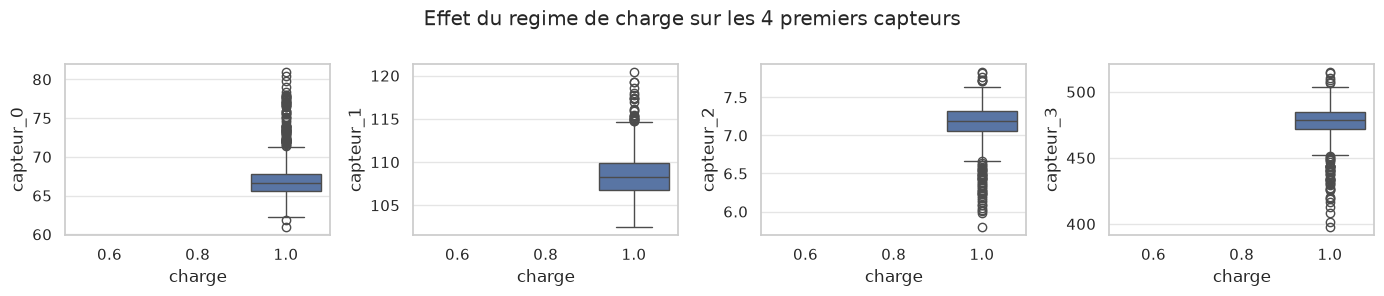

In [10]:
# --- Effet du regime de charge sur les capteurs ---
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, c in zip(axes, CAPTEURS[:4]):
    sns.boxplot(data=df, x="charge", y=c, ax=ax)
plt.suptitle("Effet du regime de charge sur les 4 premiers capteurs")
plt.tight_layout()
plt.show()

## 2. Preparation des donnees

In [11]:
# --- Cible : RUL plafonnee puis normalisee dans [0, 1] ---
df["rul_cap"] = np.minimum(df["rul"], RUL_MAX)
df["cible"] = df["rul_cap"] / RUL_MAX

# --- Decoupage par pompe : 2 pompes en validation, 8 en entrainement ---
pompes_val = [502, 509]
train = df[~df["pompe"].isin(pompes_val)].copy()
val = df[df["pompe"].isin(pompes_val)].copy()

train = train.sort_values(["pompe", "cycle"]).reset_index(drop=True)
val = val.sort_values(["pompe", "cycle"]).reset_index(drop=True)

print("entrainement :", train.shape, "| validation :", val.shape)

entrainement : (2378, 14) | validation : (469, 14)


In [12]:
# --- Couches de normalisation Keras (apprises sur l'entrainement uniquement) ---
# 1) une couche par regime, apprise sur les cycles sains du train
norm_regime = {}
for c in [0.6, 0.8, 1.0]:
    sains = train[(train["charge"] == c) & (train["rul_cap"] == RUL_MAX)]
    norm_regime[c] = layers.Normalization(axis=-1)
    norm_regime[c].adapt(sains[CAPTEURS].values.astype("float32"))

# 2) une couche globale, apprise sur tout le train
norm_global = layers.Normalization(axis=-1)
norm_global.adapt(train[CAPTEURS].values.astype("float32"))

print("couches de normalisation pretes :", len(norm_regime), "par regime + 1 globale")

couches de normalisation pretes : 3 par regime + 1 globale


E0000 00:00:1791637186.709745  249972 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [13]:
# --- Application de la normalisation ---
def normaliser(donnees):
    """Normalisation par regime : un z-score par capteur et par charge."""
    d = donnees.copy()
    for c, couche in norm_regime.items():
        lignes = d["charge"] == c
        d.loc[lignes, CAPTEURS] = couche(d.loc[lignes, CAPTEURS].values.astype("float32")).numpy()
    return d

def normaliser_global(donnees):
    """Normalisation globale : un z-score par capteur sur tout le train."""
    d = donnees.copy()
    d[CAPTEURS] = norm_global(d[CAPTEURS].values.astype("float32")).numpy()
    return d

print("fonctions de normalisation definies")

fonctions de normalisation definies


In [14]:
# --- Entrees et cibles (normalisation par regime pour le jeu principal) ---
train_n = normaliser(train)
val_n = normaliser(val)

X_train = train_n[FEATURES].values.astype("float32")   # 9 entrees
y_train = train_n["cible"].values.astype("float32")
X_val = val_n[FEATURES].values.astype("float32")
y_val = val_n["cible"].values.astype("float32")
y_val_cycles = val_n["rul_cap"].values.astype(float)   # RUL reelle en cycles

# points de coupe pour mesurer l'anticipation / les fausses alertes
DECOUPES = [5, 15, 30, 45, 60, 90, 120]
masque_coupes = val_n["rul_cap"].isin(DECOUPES).values

print("X_train :", X_train.shape, "| X_val :", X_val.shape, "| points de coupe :", int(masque_coupes.sum()))

X_train : (2378, 9) | X_val : (469, 9) | points de coupe : 14


## 3. Metriques et suivi des experiences

In [15]:
# --- Metriques d'evaluation ---
def rmse(y_vrai, y_pred):
    return float(np.sqrt(np.mean((y_vrai - y_pred) ** 2)))

def score_nasa(y_vrai, y_pred):
    """Score asymetrique NASA : penalise davantage les predictions en retard (sur-estimation de la RUL)."""
    d = y_pred - y_vrai
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def taux_alerte(y_vrai, y_pred):
    """(taux d'anticipation, taux de fausses alertes)."""
    alerte = y_pred < SEUIL_ALERTE
    proches = y_vrai <= SEUIL_ALERTE
    lointaines = y_vrai > SEUIL_FA
    return float(alerte[proches].mean()), float(alerte[lointaines].mean())

def evaluer(modele, X):
    """Predictions ramenees en cycles, bornees a [0, RUL_MAX], et metriques associees."""
    pred = np.clip(RUL_MAX * modele.predict(X, verbose=0).ravel(), 0, RUL_MAX)
    a, f = taux_alerte(y_val_cycles[masque_coupes], pred[masque_coupes])
    return {"rmse": rmse(y_val_cycles, pred),
            "score": score_nasa(y_val_cycles, pred),
            "anticipation": a,
            "fausses_alertes": f}, pred

print("metriques definies : rmse, score_nasa, taux_alerte, evaluer")

metriques definies : rmse, score_nasa, taux_alerte, evaluer


In [16]:
# --- Journal des experiences + suivi MLflow ---
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow_jalon1.db")
mlflow.set_experiment("uc5_jalon1")
journal = []

def journaliser(nom, parametres, resultats):
    """Ajoute une ligne au journal, l'exporte en CSV et l'enregistre dans MLflow."""
    journal.append({"jalon": 1, "nom": nom, **parametres, **resultats})
    pd.DataFrame(journal).to_csv("journal_jalon1.csv", index=False)
    with mlflow.start_run(run_name=nom):
        mlflow.log_params({k: str(v) for k, v in parametres.items()})
        mlflow.log_metrics({k: float(v) for k, v in resultats.items() if np.isfinite(v)})
    print(nom, "->", {k: round(v, 2) for k, v in resultats.items()})
    return journal[-1]

print("journal pret")

2026/10/10 12:59:54 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/10 12:59:54 INFO mlflow.store.db.utils: Updating database tables
2026/10/10 13:00:02 INFO mlflow.tracking.fluent: Experiment with name 'uc5_jalon1' does not exist. Creating a new experiment.


journal pret


In [17]:
# --- Fabriques communes a toutes les experiences ---
def construire_modele(nb_entrees):
    """MLP 64-32-1 : architecture de reference, stable sur ce petit jeu de donnees."""
    return keras.Sequential([
        keras.Input(shape=(nb_entrees,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])

def entrainer(modele, X_tr, y_tr, X_va, y_va, epochs=150, batch_size=256, perte="mse"):
    """Compile (Adam) et entraine le modele avec la perte choisie, sans afficher la progression."""
    modele.compile(optimizer="adam", loss=perte)
    modele.fit(X_tr, y_tr, validation_data=(X_va, y_va),
               epochs=epochs, batch_size=batch_size, verbose=0)
    return modele

print("fabriques definies : construire_modele, entrainer")

fabriques definies : construire_modele, entrainer


## 4. Modele de reference

In [18]:
# --- Modele de reference : 9 entrees (8 capteurs + charge), normalisation par regime ---
reference = construire_modele(X_train.shape[1])
entrainer(reference, X_train, y_train, X_val, y_val)

res_ref, pred_ref = evaluer(reference, X_val)
journaliser("reference (9 entrees, regime)",
            {"normalisation": "regime", "k": 1, "perte": "mse", "features": 9}, res_ref)

reference (9 entrees, regime) -> {'rmse': 17.26, 'score': 3964.46, 'anticipation': 0.67, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'reference (9 entrees, regime)',
 'normalisation': 'regime',
 'k': 1,
 'perte': 'mse',
 'features': 9,
 'rmse': 17.26215135961085,
 'score': 3964.458592791393,
 'anticipation': 0.6666666666666666,
 'fausses_alertes': 0.0}

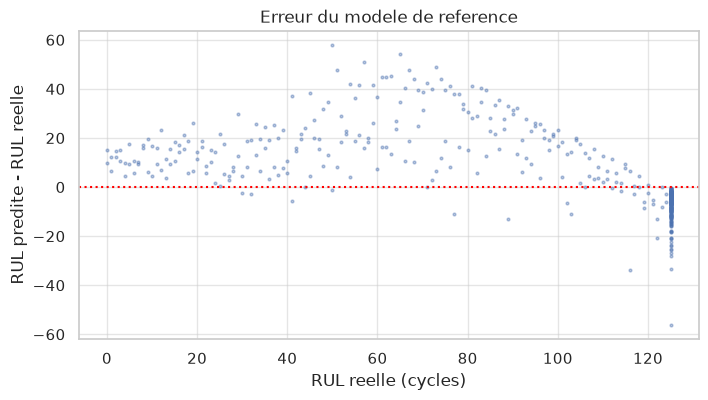

In [19]:
# --- Erreur du modele de reference en fonction de la RUL reelle ---
ecart = pred_ref - y_val_cycles
plt.figure(figsize=(8, 4))
plt.scatter(y_val_cycles, ecart, s=4, alpha=0.4)
plt.axhline(0, color="red", linestyle=":")
plt.xlabel("RUL reelle (cycles)")
plt.ylabel("RUL predite - RUL reelle")
plt.title("Erreur du modele de reference")
plt.show()

In [20]:
# --- Biais moyen (predite - reelle) ---
print("biais moyen :", round(float(ecart.mean()), 2), "cycles")

biais moyen : 5.22 cycles


## 5. Modele optimal a 3 entrees (capteur_4, capteur_5, charge)

On teste les deux strategies de normalisation sur le meme modele reduit :
normalisation **globale** puis normalisation **par regime**.

In [21]:
# --- Modele a 3 entrees + normalisation GLOBALE ---
train_g = normaliser_global(train)
val_g = normaliser_global(val)

Xg_train = train_g[FEATURES_3].values.astype("float32")
yg_train = train_g["cible"].values.astype("float32")
Xg_val = val_g[FEATURES_3].values.astype("float32")
yg_val = val_g["cible"].values.astype("float32")

modele_global = construire_modele(Xg_train.shape[1])
entrainer(modele_global, Xg_train, yg_train, Xg_val, yg_val)

res_global, _ = evaluer(modele_global, Xg_val)
journaliser("3 entrees - normalisation globale",
            {"normalisation": "globale", "k": 1, "perte": "mse", "features": 3}, res_global)

3 entrees - normalisation globale -> {'rmse': 14.13, 'score': 1927.36, 'anticipation': 1.0, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': '3 entrees - normalisation globale',
 'normalisation': 'globale',
 'k': 1,
 'perte': 'mse',
 'features': 3,
 'rmse': 14.12527801031786,
 'score': 1927.3631856266002,
 'anticipation': 1.0,
 'fausses_alertes': 0.0}

In [22]:
# --- Modele a 3 entrees + normalisation par REGIME (meilleur modele) ---
X3_train = train_n[FEATURES_3].values.astype("float32")
y3_train = train_n["cible"].values.astype("float32")
X3_val = val_n[FEATURES_3].values.astype("float32")

modele_regime = construire_modele(X3_train.shape[1])
entrainer(modele_regime, X3_train, y3_train, X3_val, y_val)

res_regime, pred_regime = evaluer(modele_regime, X3_val)
journaliser("3 entrees - normalisation regime",
            {"normalisation": "regime", "k": 1, "perte": "mse", "features": 3}, res_regime)

3 entrees - normalisation regime -> {'rmse': 13.62, 'score': 1767.63, 'anticipation': 1.0, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': '3 entrees - normalisation regime',
 'normalisation': 'regime',
 'k': 1,
 'perte': 'mse',
 'features': 3,
 'rmse': 13.616111128108209,
 'score': 1767.630948861005,
 'anticipation': 1.0,
 'fausses_alertes': 0.0}

In [23]:
# --- Comparaison des normalisations sur le modele a 3 entrees ---
pd.DataFrame({
    "normalisation": ["globale", "regime"],
    "RMSE": [res_global["rmse"], res_regime["rmse"]],
    "score": [res_global["score"], res_regime["score"]],
    "anticipation": [res_global["anticipation"], res_regime["anticipation"]],
    "fausses alertes": [res_global["fausses_alertes"], res_regime["fausses_alertes"]],
})

,normalisation,RMSE,score,anticipation,fausses alertes
0,globale,14.125278,1927.363186,1.0,0.0
1,regime,13.616111,1767.630949,1.0,0.0


## 6. Fonction de perte : MSE vs pertes asymetriques

Le score NASA est **asymetrique** : il penalise davantage les predictions en retard (sur-estimation de la RUL) via `exp(d/10)` que les predictions en avance via `exp(-d/13)`, ou `d` est l'erreur en cycles. On compare ici trois pertes sur le meilleur modele (3 entrees, normalisation par regime, k=1) :

- **MSE** : reference, erreur quadratique symetrique ;
- **asymetrique ponderee** : MSE dont la sur-estimation est penalisee `PENALITE_SURESTIMATION` fois ;
- **inspiree du score** : perte exponentielle calquee sur le score NASA (erreur en cycles).


In [24]:
# --- Fonctions de perte asymetriques ---
# 1) Version ponderee : on penalise davantage la sur-estimation de la RUL
#    (annoncer une duree de vie trop longue est plus dangereux qu'une alerte precoce).
PENALITE_SURESTIMATION = 3.0

def perte_asymetrique(y_vrai, y_pred):
    erreur = y_pred - y_vrai
    return tf.reduce_mean(tf.where(erreur > 0,
                                   PENALITE_SURESTIMATION * tf.square(erreur),
                                   tf.square(erreur)))

# 2) Version inspiree du score NASA : erreur ramenee en cycles puis forme exponentielle
#    du score (sur-estimation penalisee plus vite car 1/10 > 1/13). L'erreur est bornee
#    pour eviter l'explosion du gradient en debut d'entrainement.
def perte_score(y_vrai, y_pred):
    d = tf.clip_by_value((y_pred - y_vrai) * RUL_MAX, -30.0, 30.0)
    return tf.reduce_mean(tf.where(d < 0, tf.exp(-d / 13.0) - 1.0, tf.exp(d / 10.0) - 1.0))

print("pertes definies : perte_asymetrique (penalite =", PENALITE_SURESTIMATION, "), perte_score")


pertes definies : perte_asymetrique (penalite = 3.0 ), perte_score


In [25]:
# --- Meilleur modele (3 entrees, regime, k=1) avec perte asymetrique ---
modele_asym = construire_modele(X3_train.shape[1])
entrainer(modele_asym, X3_train, y3_train, X3_val, y_val, perte=perte_asymetrique)

res_asym, pred_asym = evaluer(modele_asym, X3_val)
journaliser("3 entrees regime - perte asymetrique",
            {"normalisation": "regime", "k": 1, "perte": "asymetrique", "features": 3}, res_asym)

3 entrees regime - perte asymetrique -> {'rmse': 18.41, 'score': 1911.07, 'anticipation': 1.0, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': '3 entrees regime - perte asymetrique',
 'normalisation': 'regime',
 'k': 1,
 'perte': 'asymetrique',
 'features': 3,
 'rmse': 18.41394253373456,
 'score': 1911.069757272511,
 'anticipation': 1.0,
 'fausses_alertes': 0.0}

In [26]:
# --- Meilleur modele (3 entrees, regime, k=1) avec perte inspiree du score ---
modele_score = construire_modele(X3_train.shape[1])
entrainer(modele_score, X3_train, y3_train, X3_val, y_val, perte=perte_score)

res_score, pred_score = evaluer(modele_score, X3_val)
journaliser("3 entrees regime - perte inspiree du score",
            {"normalisation": "regime", "k": 1, "perte": "score", "features": 3}, res_score)


3 entrees regime - perte inspiree du score -> {'rmse': 20.17, 'score': 4831.37, 'anticipation': 1.0, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': '3 entrees regime - perte inspiree du score',
 'normalisation': 'regime',
 'k': 1,
 'perte': 'score',
 'features': 3,
 'rmse': 20.172816533870783,
 'score': 4831.372741024484,
 'anticipation': 1.0,
 'fausses_alertes': 0.0}

In [27]:
# --- Comparaison des fonctions de perte (3 entrees, regime, k=1) ---
pd.DataFrame({
    "perte": ["mse", "asymetrique", "inspiree du score"],
    "RMSE": [res_regime["rmse"], res_asym["rmse"], res_score["rmse"]],
    "score": [res_regime["score"], res_asym["score"], res_score["score"]],
    "anticipation": [res_regime["anticipation"], res_asym["anticipation"], res_score["anticipation"]],
    "fausses alertes": [res_regime["fausses_alertes"], res_asym["fausses_alertes"], res_score["fausses_alertes"]],
})


,perte,RMSE,score,anticipation,fausses alertes
0,mse,13.616111,1767.630949,1.0,0.0
1,asymetrique,18.413943,1911.069757,1.0,0.0
2,inspiree du score,20.172817,4831.372741,1.0,0.0


**Lecture.** Le score NASA n'est pas la metrique d'entrainement du MSE : les pertes asymetriques cherchent a reduire les sur-estimations tardives, ce qui peut degrader le RMSE tout en ameliorant le score. Un ecart (meme defavorable) doit donc etre argumente plutot que force : sur ce jalon, avec seulement 2 pompes de validation et 14 points de coupe, le score reste domine par quelques outliers et la cible plafonnee en biais lineaire limite le gain atteignable.


## 7. Fenetres temporelles avec le meilleur modele (3 entrees, regime)

On reprend le meilleur modele et on varie la taille de la fenetre d'entree `k` (nombre de cycles consecutifs).

In [28]:
# --- Fenetres temporelles : entree = k cycles consecutifs (3 variables x k) ---
def fenetres(donnees, k, feats=FEATURES_3):
    """Construit les fenetres glissantes de k cycles pour chaque pompe."""
    d = donnees.sort_values(["pompe", "cycle"]).reset_index(drop=True)
    X = []
    for _, g in d.groupby("pompe"):
        v = g[feats].values.astype("float32")
        v = np.vstack([np.tile(v[0], (k - 1, 1)), v])   # repetition du 1er cycle pour amorcer
        for i in range(len(g)):
            X.append(v[i:i + k].ravel())
    return (np.array(X, dtype="float32"),
            d["rul_cap"].values.astype(float),
            d["cible"].values.astype("float32"))

def bruit_moyen(pred):
    """Ecart-type moyen des predictions intra-pompe (stabilite du signal)."""
    return float(np.mean([pred[val_n["pompe"].values == p].std() for p in pompes_val]))

print("fonctions definies : fenetres, bruit_moyen")

fonctions definies : fenetres, bruit_moyen


In [29]:
# --- Meilleur modele (3 entrees, regime) avec fenetre k = 5 ---
k = 5
Xk_train, _, yk_train = fenetres(train_n, k)
Xk_val, _, yk_val = fenetres(val_n, k)

modele_k5 = construire_modele(Xk_train.shape[1])
entrainer(modele_k5, Xk_train, yk_train, Xk_val, yk_val)

res_k5, pred_k5 = evaluer(modele_k5, Xk_val)
journaliser(f"3 entrees regime - fenetre k={k}",
            {"normalisation": "regime", "k": k, "perte": "mse", "features": 3},
            {**res_k5, "bruit": bruit_moyen(pred_k5)})

3 entrees regime - fenetre k=5 -> {'rmse': 12.75, 'score': 1504.73, 'anticipation': 1.0, 'fausses_alertes': 0.0, 'bruit': 39.26}


{'jalon': 1,
 'nom': '3 entrees regime - fenetre k=5',
 'normalisation': 'regime',
 'k': 5,
 'perte': 'mse',
 'features': 3,
 'rmse': 12.745172397950064,
 'score': 1504.7328550732368,
 'anticipation': 1.0,
 'fausses_alertes': 0.0,
 'bruit': 39.25798034667969}

In [30]:
# --- Meilleur modele (3 entrees, regime) avec fenetre k = 15 ---
k = 15
Xk_train, _, yk_train = fenetres(train_n, k)
Xk_val, _, yk_val = fenetres(val_n, k)

modele_k15 = construire_modele(Xk_train.shape[1])
entrainer(modele_k15, Xk_train, yk_train, Xk_val, yk_val)

res_k15, pred_k15 = evaluer(modele_k15, Xk_val)
journaliser(f"3 entrees regime - fenetre k={k}",
            {"normalisation": "regime", "k": k, "perte": "mse", "features": 3},
            {**res_k15, "bruit": bruit_moyen(pred_k15)})

3 entrees regime - fenetre k=15 -> {'rmse': 15.91, 'score': 2695.56, 'anticipation': 1.0, 'fausses_alertes': 0.0, 'bruit': 44.16}


{'jalon': 1,
 'nom': '3 entrees regime - fenetre k=15',
 'normalisation': 'regime',
 'k': 15,
 'perte': 'mse',
 'features': 3,
 'rmse': 15.910803954741464,
 'score': 2695.5581128488534,
 'anticipation': 1.0,
 'fausses_alertes': 0.0,
 'bruit': 44.156864166259766}

In [31]:
# --- Meilleur modele (3 entrees, regime) avec fenetre k = 30 ---
k = 30
Xk_train, _, yk_train = fenetres(train_n, k)
Xk_val, _, yk_val = fenetres(val_n, k)

modele_k30 = construire_modele(Xk_train.shape[1])
entrainer(modele_k30, Xk_train, yk_train, Xk_val, yk_val)

res_k30, pred_k30 = evaluer(modele_k30, Xk_val)
journaliser(f"3 entrees regime - fenetre k={k}",
            {"normalisation": "regime", "k": k, "perte": "mse", "features": 3},
            {**res_k30, "bruit": bruit_moyen(pred_k30)})

3 entrees regime - fenetre k=30 -> {'rmse': 21.11, 'score': 13538.04, 'anticipation': 0.67, 'fausses_alertes': 0.0, 'bruit': 33.89}


{'jalon': 1,
 'nom': '3 entrees regime - fenetre k=30',
 'normalisation': 'regime',
 'k': 30,
 'perte': 'mse',
 'features': 3,
 'rmse': 21.10514042225137,
 'score': 13538.044551799112,
 'anticipation': 0.6666666666666666,
 'fausses_alertes': 0.0,
 'bruit': 33.89085006713867}

In [32]:
# --- Recap des performances selon la taille de fenetre ---
pd.DataFrame([
    {"k": 5, **res_k5, "bruit": bruit_moyen(pred_k5)},
    {"k": 15, **res_k15, "bruit": bruit_moyen(pred_k15)},
    {"k": 30, **res_k30, "bruit": bruit_moyen(pred_k30)},
])

,k,rmse,score,anticipation,fausses_alertes,bruit
0,5,12.745172,1504.732855,1.000000,0.0,39.257980
1,15,15.910804,2695.558113,1.000000,0.0,44.156864
2,30,21.105140,13538.044552,0.666667,0.0,33.890850


## 8. Synthese

In [33]:
# --- Journal complet des experiences ---
pd.DataFrame(journal)

,jalon,nom,normalisation,k,perte,features,rmse,score,anticipation,fausses_alertes,bruit
0,1,"reference (9 entrees, regime)",regime,1,mse,9,17.262151,3964.458593,0.666667,0.0,NaN
1,1,3 entrees - normalisation globale,globale,1,mse,3,14.125278,1927.363186,1.000000,0.0,NaN
2,1,3 entrees - normalisation regime,regime,1,mse,3,13.616111,1767.630949,1.000000,0.0,NaN
3,1,3 entrees regime - perte asymetrique,regime,1,asymetrique,3,18.413943,1911.069757,1.000000,0.0,NaN
4,1,3 entrees regime - perte inspiree du score,regime,1,score,3,20.172817,4831.372741,1.000000,0.0,NaN
5,1,3 entrees regime - fenetre k=5,regime,5,mse,3,12.745172,1504.732855,1.000000,0.0,39.257980
6,1,3 entrees regime - fenetre k=15,regime,15,mse,3,15.910804,2695.558113,1.000000,0.0,44.156864
7,1,3 entrees regime - fenetre k=30,regime,30,mse,3,21.105140,13538.044552,0.666667,0.0,33.890850
